# 06 - SOTA Fine-Tuning: MobileNetV2

Fine-tune an ImageNet-pretrained **MobileNetV2** on the same Intel Image
Classification splits used by Model A/B (notebooks 02/03), and evaluate it
on the held-out test set using the same metrics (accuracy, precision,
recall, confusion matrix, parameter count, model size) so it can be
compared directly in `08_final_comparison.ipynb`.

In [1]:
# --- Environment setup (Google Colab + shared Google Drive) ---
import os

try:
    from google.colab import drive
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    # Mount the team's shared Drive - this is where 01_data_preparation.ipynb
    # cached the resized/normalized dataset, and where we save checkpoints +
    # results so nobody has to download large files to their own PC.
    drive.mount("/content/drive")
    DRIVE_ROOT = "/content/drive/MyDrive/EN3150-A03-Resource-Constrained-CNN"
else:
    # Local fallback (e.g. running outside Colab) - adjust as needed.
    DRIVE_ROOT = os.path.abspath("..")

# MobileNetV2 ships with tensorflow.keras.applications - no extra installs needed.

print("IN_COLAB:", IN_COLAB)
print("DRIVE_ROOT:", DRIVE_ROOT)


Mounted at /content/drive
IN_COLAB: True
DRIVE_ROOT: /content/drive/MyDrive/EN3150-A03-Resource-Constrained-CNN


## 1. Config

In [2]:
# --- Config for this notebook (defined here, not in a shared file) ---
CONFIG = {
    "image_size": 64,          # resolution of the cached dataset (<= 64x64 per spec)
    "channels": 3,
    "train_ratio": 0.70,
    "val_ratio": 0.15,
    "test_ratio": 0.15,
    "random_seed": 42,
    "batch_size": 32,
    "epochs": 20,               # total epochs, split across the two phases below
    "epochs_frozen": 8,         # phase 1: train the new head only, backbone frozen
    "epochs_fine_tune": 12,     # phase 2: unfreeze top backbone layers, train jointly
    "fine_tune_unfreeze_fraction": 0.2,  # unfreeze the last 20% of backbone layers
    "lr_frozen": 1e-3,
    "lr_fine_tune": 1e-5,       # much lower LR once the pretrained backbone is unfrozen
    "dataset_name": "Intel Image Classification",
    "num_classes": 6,
    "class_names": ["buildings", "forest", "glacier", "mountain", "sea", "street"],
    "sota_input_size": 96,      # MobileNetV2's smallest practical input size (see Sec. 4)
}
assert CONFIG["epochs_frozen"] + CONFIG["epochs_fine_tune"] == CONFIG["epochs"]

# --- Paths (mirrors the layout used by 01_data_preparation.ipynb) ---
PROCESSED_DIR = os.path.join(DRIVE_ROOT, "data", "processed", "intel-image-classification")
CHECKPOINT_DIR = os.path.join(DRIVE_ROOT, "models", "checkpoints", "mobilenet")
FINAL_MODEL_DIR = os.path.join(DRIVE_ROOT, "models", "final")
FIGURES_DIR = os.path.join(DRIVE_ROOT, "results", "figures", "mobilenet")
CONFUSION_DIR = os.path.join(DRIVE_ROOT, "results", "confusion_matrices")
METRICS_DIR = os.path.join(DRIVE_ROOT, "results", "metrics")

for d in (CHECKPOINT_DIR, FINAL_MODEL_DIR, FIGURES_DIR, CONFUSION_DIR, METRICS_DIR):
    os.makedirs(d, exist_ok=True)

CONFIG


{'image_size': 64,
 'channels': 3,
 'train_ratio': 0.7,
 'val_ratio': 0.15,
 'test_ratio': 0.15,
 'random_seed': 42,
 'batch_size': 32,
 'epochs': 20,
 'epochs_frozen': 8,
 'epochs_fine_tune': 12,
 'fine_tune_unfreeze_fraction': 0.2,
 'lr_frozen': 0.001,
 'lr_fine_tune': 1e-05,
 'dataset_name': 'Intel Image Classification',
 'num_classes': 6,
 'class_names': ['buildings',
  'forest',
  'glacier',
  'mountain',
  'sea',
  'street'],
 'sota_input_size': 96}

## 2. Imports

In [3]:
import json
import random
import time

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    precision_score,
    recall_score,
)

print("TensorFlow:", tf.__version__)
print("GPU available:", tf.config.list_physical_devices("GPU"))


TensorFlow: 2.20.0
GPU available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 3. Seed

In [4]:
SEED = CONFIG["random_seed"]
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)


## 4. Load Prepared Data

In [5]:
# Load the same 64x64 float32 [0, 1] splits produced by 01_data_preparation.ipynb.
X_train = np.load(os.path.join(PROCESSED_DIR, "X_train.npy"))
y_train = np.load(os.path.join(PROCESSED_DIR, "y_train.npy"))
X_val = np.load(os.path.join(PROCESSED_DIR, "X_val.npy"))
y_val = np.load(os.path.join(PROCESSED_DIR, "y_val.npy"))
X_test = np.load(os.path.join(PROCESSED_DIR, "X_test.npy"))
y_test = np.load(os.path.join(PROCESSED_DIR, "y_test.npy"))

with open(os.path.join(PROCESSED_DIR, "class_names.json")) as f:
    class_names = json.load(f)
assert class_names == CONFIG["class_names"], "class_names.json does not match CONFIG - re-check notebook 01"

print("train/val/test sizes:", len(X_train), len(X_val), len(X_test))
print("image shape:", X_train.shape[1:], "dtype:", X_train.dtype)


train/val/test sizes: 11923 2555 2556
image shape: (64, 64, 3) dtype: float32


In [6]:
# NOTE: MobileNetV2 was pretrained on 224x224 ImageNet crops; its 5 stride-2
# stages downsample by 32x overall, so anything much smaller than ~96x96
# leaves the final feature map at 1x1 or 2x2 and the ImageNet weights stop
# being useful. Our cached images are only 64x64, so we upsample on the fly
# (bilinear) to CONFIG["sota_input_size"] = 96 inside the tf.data pipeline,
# rather than storing a second, larger copy of the dataset on Drive. This is
# "fake resolution" - it adds no real information - and is exactly the kind
# of trade-off we call out when comparing this SOTA fine-tune against the
# from-scratch Model A/B in Section 15 / notebook 08.
IMG_SIZE = CONFIG["sota_input_size"]


def make_dataset(X, y, training):
    ds = tf.data.Dataset.from_tensor_slices((X, y))
    if training:
        ds = ds.shuffle(buffer_size=len(X), seed=SEED)

    def _prepare(image, label):
        image = tf.image.resize(image, (IMG_SIZE, IMG_SIZE), method="bilinear")
        # Undo notebook 01's /255 normalization, then apply MobileNetV2's own
        # preprocessing (rescales to [-1, 1]) so the pretrained backbone sees
        # inputs in the range it was originally trained on.
        image = preprocess_input(image * 255.0)
        return image, label

    ds = ds.map(_prepare, num_parallel_calls=tf.data.AUTOTUNE)
    ds = ds.batch(CONFIG["batch_size"])
    return ds.prefetch(tf.data.AUTOTUNE)


train_ds = make_dataset(X_train, y_train, training=True)
val_ds = make_dataset(X_val, y_val, training=False)
test_ds = make_dataset(X_test, y_test, training=False)


## 5. Build MobileNet (Pretrained Backbone + New Head)

In [7]:
input_shape = (IMG_SIZE, IMG_SIZE, CONFIG["channels"])

base_model = MobileNetV2(input_shape=input_shape, include_top=False, weights="imagenet")
base_model.trainable = False  # Phase 1: freeze the pretrained backbone entirely (Section 8).

inputs = keras.Input(shape=input_shape)
# `training=False` here is deliberate and permanent: it keeps every BatchNorm
# layer inside the backbone in inference mode (using its frozen ImageNet
# running statistics) for BOTH phases, even after base_model.trainable is
# flipped back to True in Phase 2. This is the standard recipe for
# fine-tuning a BatchNorm-heavy backbone with a small batch size - otherwise
# the BN layers would start updating their running stats from our much
# smaller/narrower dataset and can destroy the pretrained features.
x = base_model(inputs, training=False)
x = keras.layers.GlobalAveragePooling2D()(x)
x = keras.layers.Dropout(0.2)(x)
outputs = keras.layers.Dense(CONFIG["num_classes"], activation="softmax")(x)
model = keras.Model(inputs, outputs, name="mobilenetv2_intel_scenes")


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


## 6. Model Summary

In [8]:
model.summary()


Model: "mobilenetv2_intel_scenes"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_96             │ (None, 3, 3, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 6)              │         7,686 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,265,670 (8.64 MB)

 Trainable params: 7,686 (30.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

## 7. Parameter Count

In [9]:
total_params = model.count_params()
trainable_params = int(sum(np.prod(v.shape) for v in model.trainable_weights))
non_trainable_params = total_params - trainable_params

print(f"Total parameters:              {total_params:,}")
print(f"Trainable (Phase 1, head only): {trainable_params:,}")
print(f"Non-trainable (frozen backbone): {non_trainable_params:,}")


Total parameters:              2,265,670
Trainable (Phase 1, head only): 7,686
Non-trainable (frozen backbone): 2,257,984


## 8. Fine-Tuning Strategy

We fine-tune in two phases rather than unfreezing everything at once, to
avoid destroying the pretrained ImageNet features with large, noisy
gradients early in training:

1. **Phase 1 - frozen backbone (`CONFIG["epochs_frozen"]` = 8 epochs).**
   `base_model.trainable = False`; only the new `GlobalAveragePooling2D ->
   Dropout -> Dense(6, softmax)` head is trained, with a normal learning
   rate (`lr_frozen = 1e-3`). This lets the randomly-initialized head adapt
   to MobileNetV2's features without back-propagating large gradients
   through the pretrained weights.
2. **Phase 2 - partial unfreeze / fine-tune (`CONFIG["epochs_fine_tune"]` =
   12 epochs).** We unfreeze only the **last `fine_tune_unfreeze_fraction`
   = 20%** of backbone layers (the deepest, most task-specific blocks) and
   keep the earlier ~80% (generic, low-level edge/texture/color filters)
   frozen - those transfer well across image domains and are the most
   expensive to re-learn safely. We recompile with a much lower learning
   rate (`lr_fine_tune = 1e-5`, 100x smaller) so the now-trainable backbone
   layers move gently instead of overwriting their pretrained weights.

Both phases together total `20` epochs, satisfying the assignment's
`>= 20` epoch requirement. `ModelCheckpoint(monitor="val_loss")` runs across
*both* phases and is never reset, so the checkpoint that is finally
reloaded for evaluation is the best epoch seen overall, whichever phase it
came from.

## 9. Training

In [10]:
ckpt_path = os.path.join(CHECKPOINT_DIR, "best.keras")

checkpoint_cb = keras.callbacks.ModelCheckpoint(
    ckpt_path, monitor="val_loss", save_best_only=True, verbose=1,
)

# --- Phase 1: train the new head only, backbone frozen ---
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=CONFIG["lr_frozen"]),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

t0 = time.time()
history_frozen = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=CONFIG["epochs_frozen"],
    callbacks=[checkpoint_cb],
)
phase1_time = time.time() - t0
phase1_epochs = CONFIG["epochs_frozen"]
print(f"Phase 1 ({phase1_epochs} epochs) took {phase1_time:.1f}s "
      f"({phase1_time / phase1_epochs:.1f}s/epoch)")


Epoch 1/8
373/373 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.7246 - loss: 0.7379
Epoch 1: val_loss improved from None to 0.34891, saving model to /content/drive/MyDrive/EN3150-A03-Resource-Constrained-CNN/models/checkpoints/mobilenet/best.keras

Epoch 1: finished saving model to /content/drive/MyDrive/EN3150-A03-Resource-Constrained-CNN/models/checkpoints/mobilenet/best.keras
373/373 ━━━━━━━━━━━━━━━━━━━━ 32s 53ms/step - accuracy: 0.8207 - loss: 0.4893 - val_accuracy: 0.8767 - val_loss: 0.3489
Epoch 2/8
368/373 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.8832 - loss: 0.3271
Epoch 2: val_loss improved from 0.34891 to 0.31078, saving model to /content/drive/MyDrive/EN3150-A03-Resource-Constrained-CNN/models/checkpoints/mobilenet/best.keras

Epoch 2: finished saving model to /content/drive/MyDrive/EN3150-A03-Resource-Constrained-CNN/models/checkpoints/mobilenet/best.keras
373/373 ━━━━━━━━━━━━━━━━━━━━ 5s 13ms/step - accuracy: 0.8866 - loss: 0.3180 - val_accuracy: 0.8885 - val_loss:

In [11]:
# --- Phase 2: unfreeze the top of the backbone, fine-tune end-to-end at a low LR ---
base_model.trainable = True

fine_tune_at = int(len(base_model.layers) * (1 - CONFIG["fine_tune_unfreeze_fraction"]))
for layer in base_model.layers[:fine_tune_at]:
    layer.trainable = False  # keep the earlier, more generic feature layers frozen

n_unfrozen = len(base_model.layers) - fine_tune_at
print(f"Unfreezing {n_unfrozen} of {len(base_model.layers)} backbone layers "
      f"(from layer {fine_tune_at} onward).")

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=CONFIG["lr_fine_tune"]),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

initial_epoch = CONFIG["epochs_frozen"]
total_epochs = CONFIG["epochs_frozen"] + CONFIG["epochs_fine_tune"]

t0 = time.time()
history_fine_tune = model.fit(
    train_ds,
    validation_data=val_ds,
    initial_epoch=initial_epoch,
    epochs=total_epochs,
    callbacks=[checkpoint_cb],
)
phase2_time = time.time() - t0
phase2_epochs = CONFIG["epochs_fine_tune"]
print(f"Phase 2 ({phase2_epochs} epochs) took {phase2_time:.1f}s "
      f"({phase2_time / phase2_epochs:.1f}s/epoch)")

avg_time_per_epoch = (phase1_time + phase2_time) / total_epochs
print(f"Average training time/epoch (both phases): {avg_time_per_epoch:.1f}s")

# Reload the best checkpoint (lowest val_loss seen across BOTH phases) before evaluating.
model = keras.models.load_model(ckpt_path)


Unfreezing 31 of 154 backbone layers (from layer 123 onward).
Epoch 9/20
373/373 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - accuracy: 0.7585 - loss: 0.7852
Epoch 9: val_loss did not improve from 0.29580
373/373 ━━━━━━━━━━━━━━━━━━━━ 36s 51ms/step - accuracy: 0.8014 - loss: 0.6192 - val_accuracy: 0.8701 - val_loss: 0.4123
Epoch 10/20
372/373 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.8666 - loss: 0.3878
Epoch 10: val_loss did not improve from 0.29580
373/373 ━━━━━━━━━━━━━━━━━━━━ 20s 18ms/step - accuracy: 0.8720 - loss: 0.3768 - val_accuracy: 0.8798 - val_loss: 0.3981
Epoch 11/20
369/373 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.8870 - loss: 0.3275
Epoch 11: val_loss did not improve from 0.29580
373/373 ━━━━━━━━━━━━━━━━━━━━ 9s 15ms/step - accuracy: 0.8909 - loss: 0.3194 - val_accuracy: 0.8849 - val_loss: 0.3814
Epoch 12/20
370/373 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.8974 - loss: 0.2851
Epoch 12: val_loss did not improve from 0.29580
373/373 ━━━━━━━━━━━━━━━━━━━━ 7s 18ms/ste

## 10. Training / Validation Loss Curves

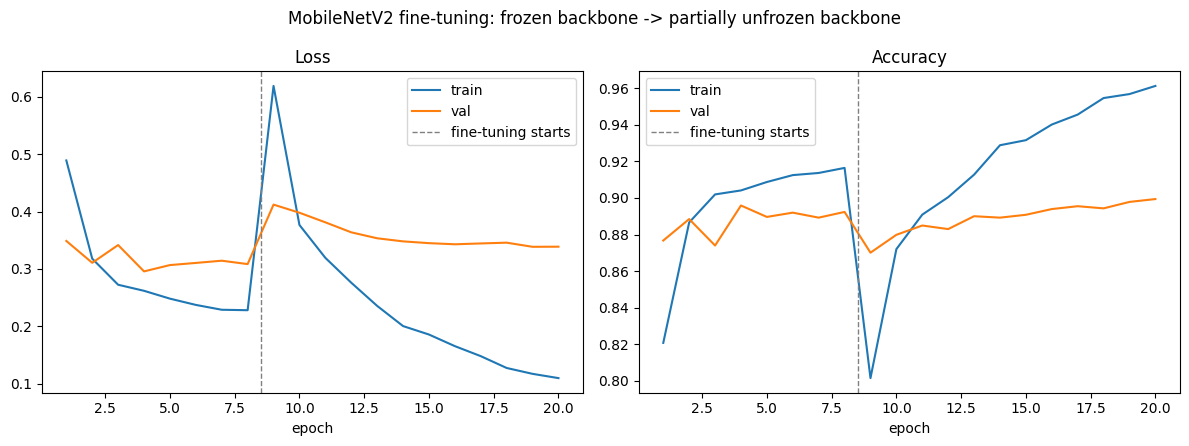

Saved: /content/drive/MyDrive/EN3150-A03-Resource-Constrained-CNN/results/figures/mobilenet/loss_curve.png


In [12]:
def concat_history(h1, h2, key):
    return h1.history[key] + h2.history[key]

epochs_range = range(1, total_epochs + 1)
train_loss = concat_history(history_frozen, history_fine_tune, "loss")
val_loss = concat_history(history_frozen, history_fine_tune, "val_loss")
train_acc = concat_history(history_frozen, history_fine_tune, "accuracy")
val_acc = concat_history(history_frozen, history_fine_tune, "val_accuracy")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].plot(epochs_range, train_loss, label="train")
axes[0].plot(epochs_range, val_loss, label="val")
axes[0].axvline(CONFIG["epochs_frozen"] + 0.5, color="gray", linestyle="--", linewidth=1,
                label="fine-tuning starts")
axes[0].set_title("Loss")
axes[0].set_xlabel("epoch")
axes[0].legend()

axes[1].plot(epochs_range, train_acc, label="train")
axes[1].plot(epochs_range, val_acc, label="val")
axes[1].axvline(CONFIG["epochs_frozen"] + 0.5, color="gray", linestyle="--", linewidth=1,
                label="fine-tuning starts")
axes[1].set_title("Accuracy")
axes[1].set_xlabel("epoch")
axes[1].legend()

plt.suptitle("MobileNetV2 fine-tuning: frozen backbone -> partially unfrozen backbone")
plt.tight_layout()
loss_curve_path = os.path.join(FIGURES_DIR, "loss_curve.png")
plt.savefig(loss_curve_path, dpi=150)
plt.show()
print("Saved:", loss_curve_path)


## 11. Test Set Evaluation

In [13]:
y_pred_probs = model.predict(test_ds)
y_pred = np.argmax(y_pred_probs, axis=1)

test_accuracy = accuracy_score(y_test, y_pred)
test_precision_macro = precision_score(y_test, y_pred, average="macro")
test_recall_macro = recall_score(y_test, y_pred, average="macro")
cm = confusion_matrix(y_test, y_pred)

print(f"Test accuracy:           {test_accuracy:.4f}")
print(f"Test precision (macro):  {test_precision_macro:.4f}")
print(f"Test recall (macro):     {test_recall_macro:.4f}")
print()
print(classification_report(y_test, y_pred, target_names=class_names))


80/80 ━━━━━━━━━━━━━━━━━━━━ 9s 78ms/step
Test accuracy:           0.9038
Test precision (macro):  0.9049
Test recall (macro):     0.9059

              precision    recall  f1-score   support

   buildings       0.93      0.93      0.93       394
      forest       0.96      0.99      0.98       412
     glacier       0.85      0.81      0.83       444
    mountain       0.83      0.84      0.84       456
         sea       0.91      0.92      0.91       417
      street       0.94      0.94      0.94       433

    accuracy                           0.90      2556
   macro avg       0.90      0.91      0.91      2556
weighted avg       0.90      0.90      0.90      2556



## 12. Confusion Matrix

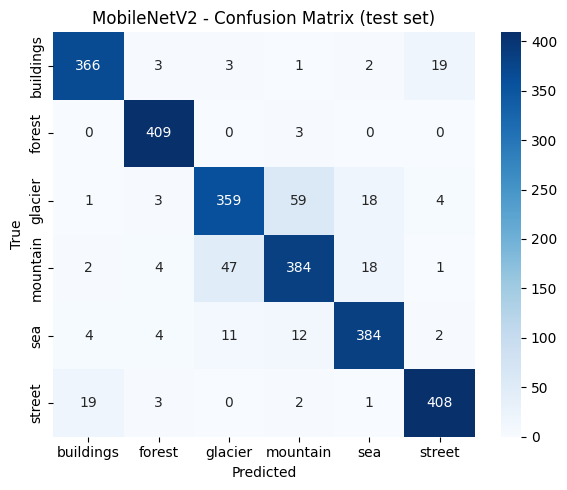

Saved: /content/drive/MyDrive/EN3150-A03-Resource-Constrained-CNN/results/confusion_matrices/mobilenet.png


In [14]:
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("MobileNetV2 - Confusion Matrix (test set)")
plt.tight_layout()
cm_path = os.path.join(CONFUSION_DIR, "mobilenet.png")
plt.savefig(cm_path, dpi=150)
plt.show()
print("Saved:", cm_path)


## 13. Model Size (MB)

In [15]:
final_model_path = os.path.join(FINAL_MODEL_DIR, "mobilenet.keras")
model.save(final_model_path)

model_size_mb = os.path.getsize(final_model_path) / (1024 ** 2)
print(f"Saved final model to: {final_model_path}")
print(f"Model size on disk: {model_size_mb:.2f} MB")


Saved final model to: /content/drive/MyDrive/EN3150-A03-Resource-Constrained-CNN/models/final/mobilenet.keras
Model size on disk: 9.26 MB


## 14. Save Results

In [16]:
metrics = {
    "model_name": "MobileNetV2",
    "dataset_name": CONFIG["dataset_name"],
    "input_size": IMG_SIZE,
    "test_accuracy": float(test_accuracy),
    "test_precision_macro": float(test_precision_macro),
    "test_recall_macro": float(test_recall_macro),
    "confusion_matrix": cm.tolist(),
    "class_names": class_names,
    "total_params": int(total_params),
    "trainable_params_phase1": int(trainable_params),
    "model_size_mb": float(model_size_mb),
    "epochs_frozen": CONFIG["epochs_frozen"],
    "epochs_fine_tune": CONFIG["epochs_fine_tune"],
    "avg_time_per_epoch_sec": float(avg_time_per_epoch),
    "history": {
        "loss": train_loss,
        "val_loss": val_loss,
        "accuracy": train_acc,
        "val_accuracy": val_acc,
    },
}

metrics_path = os.path.join(METRICS_DIR, "mobilenet.json")
with open(metrics_path, "w") as f:
    json.dump(metrics, f, indent=2)

print("Saved metrics to:", metrics_path)


Saved metrics to: /content/drive/MyDrive/EN3150-A03-Resource-Constrained-CNN/results/metrics/mobilenet.json


## 15. Conclusion

In [17]:
print(
    f"MobileNetV2 (fine-tuned, {IMG_SIZE}x{IMG_SIZE} input upsampled from "
    f"{CONFIG['image_size']}x{CONFIG['image_size']}):\n"
    f"  Test accuracy:                  {test_accuracy:.4f}\n"
    f"  Test precision/recall (macro):  {test_precision_macro:.4f} / {test_recall_macro:.4f}\n"
    f"  Total parameters:               {total_params:,}\n"
    f"  Model size on disk:             {model_size_mb:.2f} MB\n"
    f"  Avg. time/epoch:                {avg_time_per_epoch:.1f}s"
)


MobileNetV2 (fine-tuned, 96x96 input upsampled from 64x64):
  Test accuracy:                  0.9038
  Test precision/recall (macro):  0.9049 / 0.9059
  Total parameters:               2,265,670
  Model size on disk:             9.26 MB
  Avg. time/epoch:                10.0s
